Input dataset loaded successfully.
Daily dataset shape: (1075, 6)
Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00
No capacity column found. Capacity-pressure features were not created.


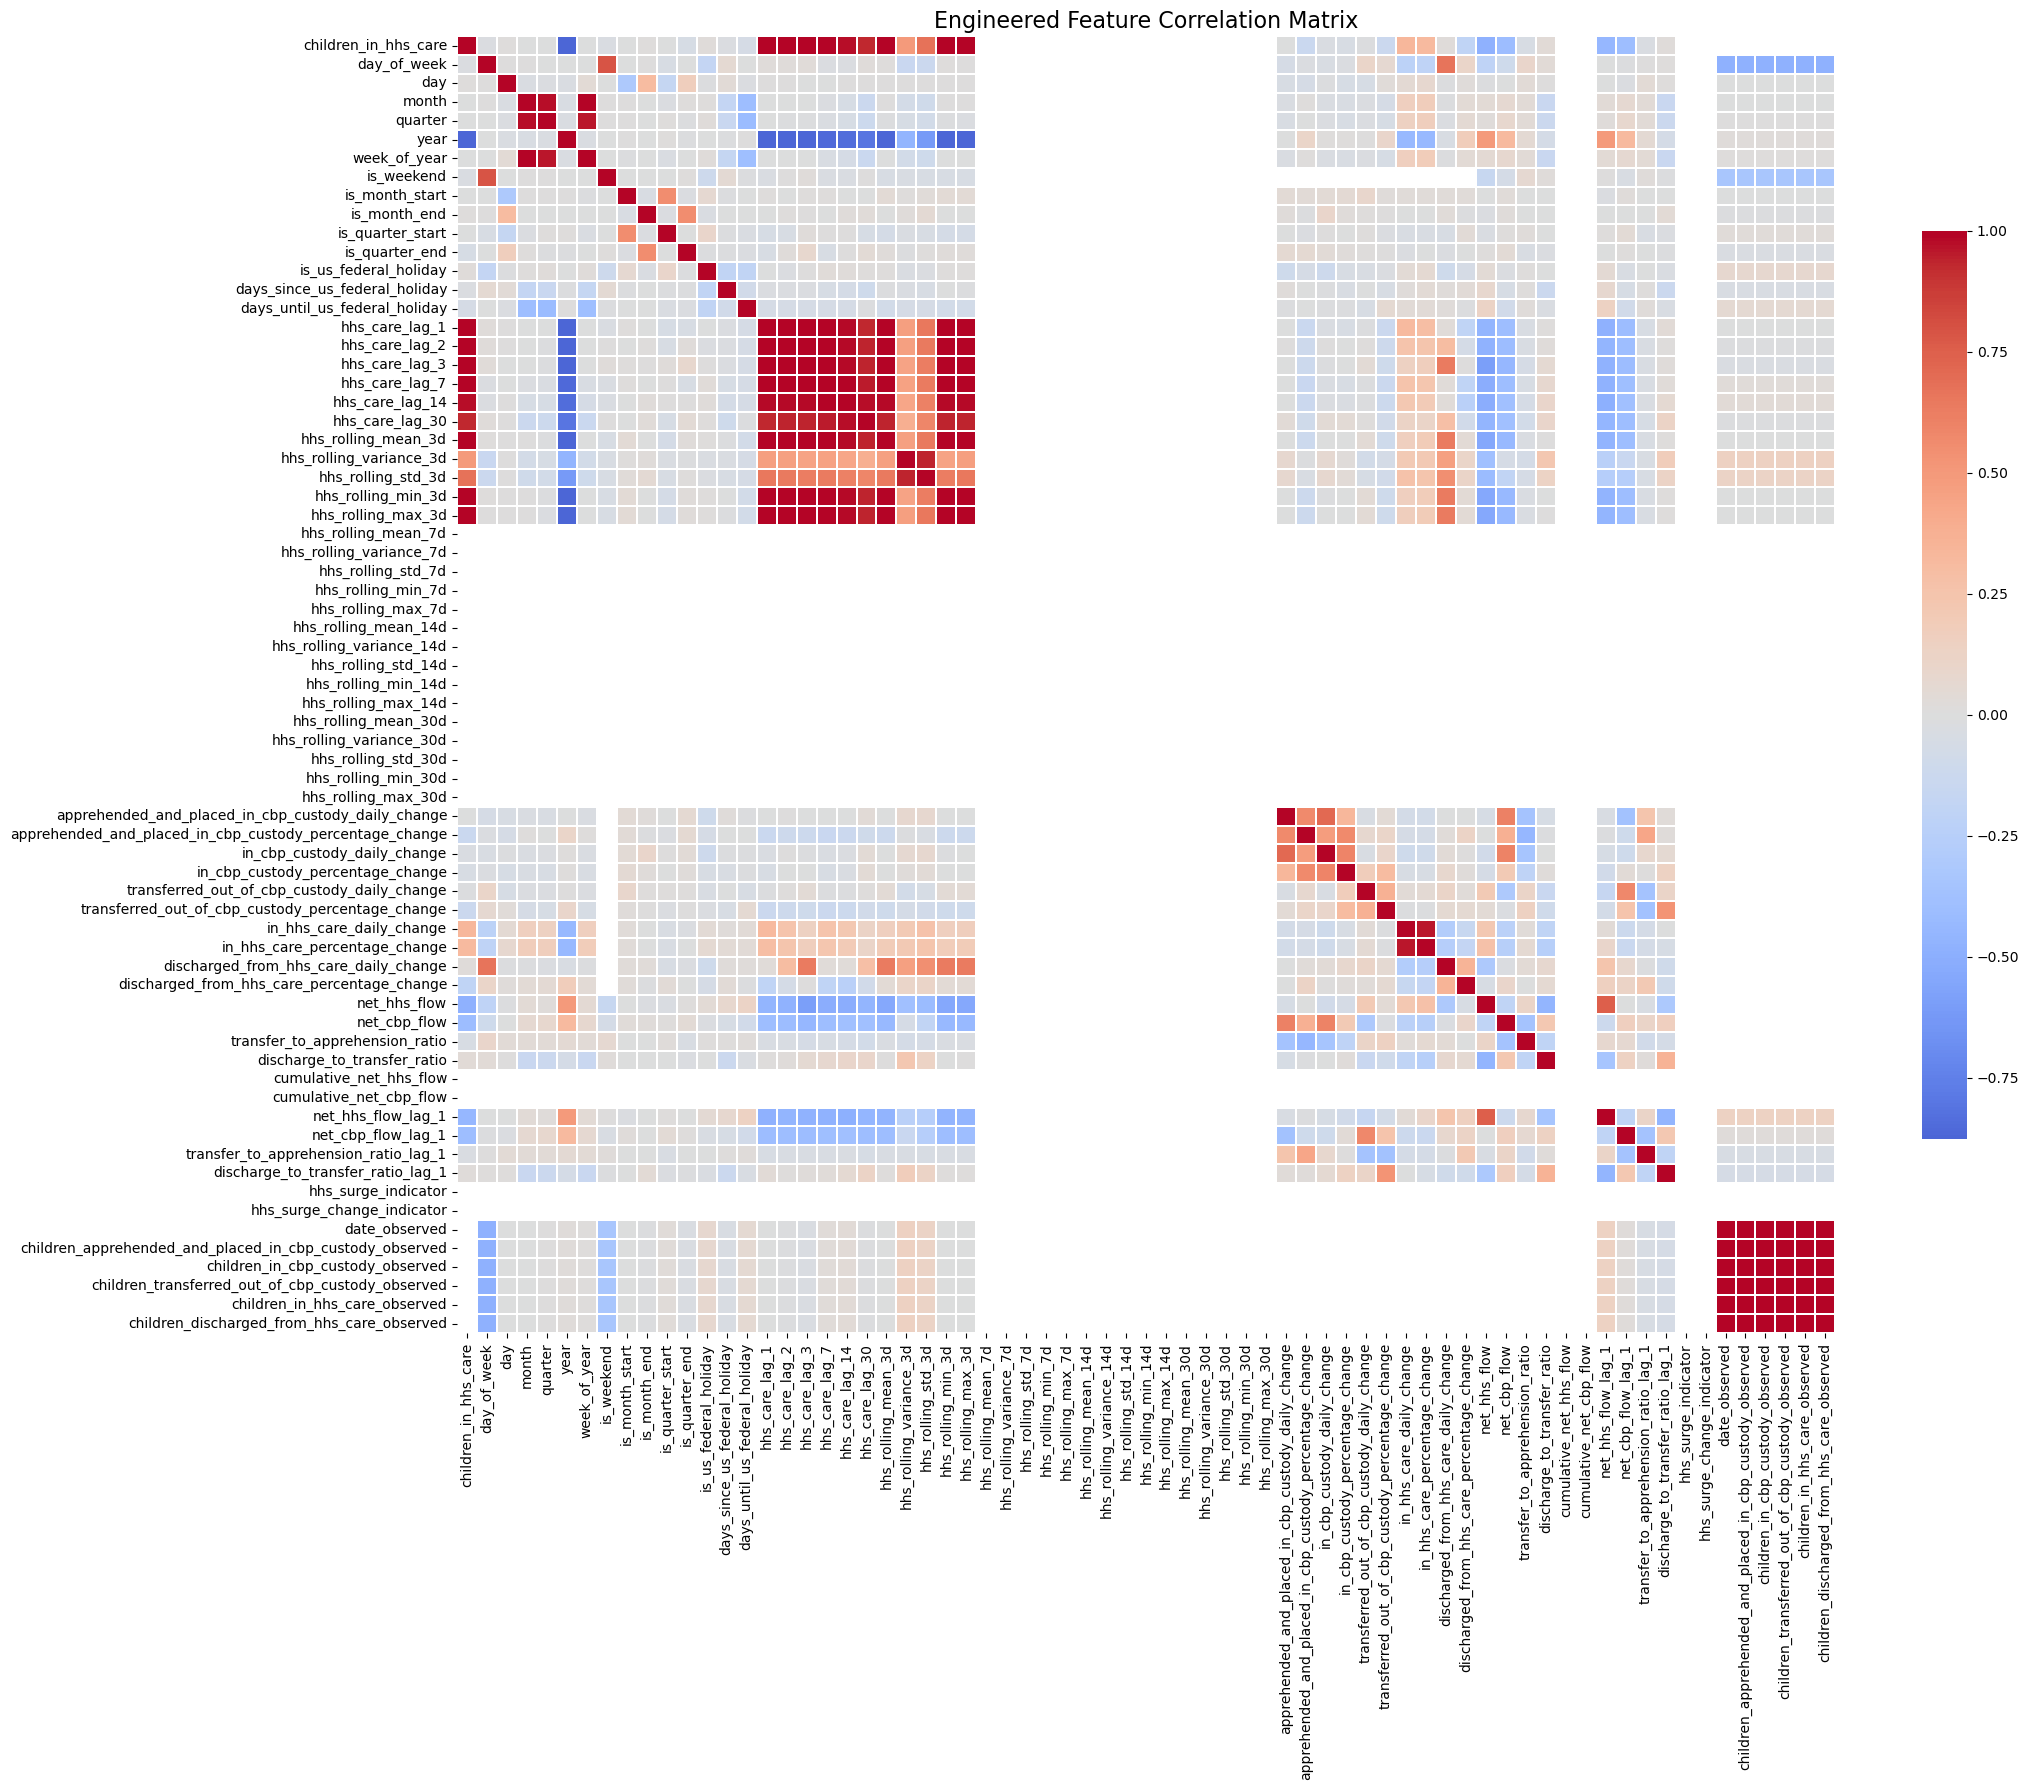


FEATURE ENGINEERING COMPLETED

Engineered dataset shape: (1075, 71)
Total engineered features: 69
High-correlation feature pairs: 65

Generated files:
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\engineered_features.csv
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\feature_dictionary.csv
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\feature_correlation.csv
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\feature_leakage_report.csv
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\feature_availability_report.csv
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\high_multicollinearity_pairs.csv
 C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\feature_correlation_heatmap.png

Feature categories:
category
Rolling Statistics    20
Calendar         

In [1]:
# Feature Engineering for Care Load and Placement Demand Forecasting

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.tseries.holiday import USFederalHolidayCalendar

# ---------------------------------------------------------
# Project paths and configuration
# ---------------------------------------------------------

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

INPUT_FILE = PROJECT_ROOT / "data" / "processed" / "cleaned_care_data.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "children_in_hhs_care"

REQUIRED_COLUMNS = [
    "date",
    "children_apprehended_and_placed_in_cbp_custody",
    "children_in_cbp_custody",
    "children_transferred_out_of_cbp_custody",
    "children_in_hhs_care",
    "children_discharged_from_hhs_care"
]

if not INPUT_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {INPUT_FILE}")

df = pd.read_csv(INPUT_FILE)

missing_columns = [col for col in REQUIRED_COLUMNS if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.dropna(subset=["date"])
df = df.sort_values("date").drop_duplicates(subset=["date"])
df = df.set_index("date")

numeric_columns = [col for col in REQUIRED_COLUMNS if col != "date"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Reindex to a complete daily calendar.
# Missing dates remain NaN; they are not treated as zero.
daily_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

df = df.reindex(daily_index)
df.index.name = "date"

original_observed_dates = set(
    pd.to_datetime(pd.read_csv(INPUT_FILE)["date"], errors="coerce").dropna()
)

df["date_observed"] = df.index.isin(original_observed_dates).astype(int)

print("Input dataset loaded successfully.")
print("Daily dataset shape:", df.shape)
print("Date range:", df.index.min(), "to", df.index.max())

# ---------------------------------------------------------
# Initialize engineered dataset
# ---------------------------------------------------------

features = pd.DataFrame(index=df.index)

features[TARGET] = df[TARGET]

feature_dictionary = []

def register_feature(name, description, category, availability, leakage_status, source):
    feature_dictionary.append({
        "feature_name": name,
        "description": description,
        "category": category,
        "forecast_time_availability": availability,
        "leakage_assessment": leakage_status,
        "source": source
    })

def add_feature(name, values, description, category,
                availability="Available before forecast origin",
                leakage_status="No direct target leakage",
                source="Historical dataset"):

    features[name] = values

    register_feature(
        name,
        description,
        category,
        availability,
        leakage_status,
        source
    )

# ---------------------------------------------------------
# Date and calendar features
# ---------------------------------------------------------

add_feature(
    "day_of_week",
    pd.Series(df.index.dayofweek, index=df.index),
    "Day of week: Monday=0 through Sunday=6.",
    "Calendar"
)

add_feature(
    "day_name",
    pd.Series(df.index.day_name(), index=df.index),
    "Name of the day of the week.",
    "Calendar"
)

add_feature(
    "day",
    pd.Series(df.index.day, index=df.index),
    "Day of the month.",
    "Calendar"
)

add_feature(
    "month",
    pd.Series(df.index.month, index=df.index),
    "Calendar month.",
    "Calendar"
)

add_feature(
    "quarter",
    pd.Series(df.index.quarter, index=df.index),
    "Calendar quarter.",
    "Calendar"
)

add_feature(
    "year",
    pd.Series(df.index.year, index=df.index),
    "Calendar year.",
    "Calendar"
)

add_feature(
    "week_of_year",
    pd.Series(df.index.isocalendar().week.astype(int).values, index=df.index),
    "ISO calendar week number.",
    "Calendar"
)

add_feature(
    "is_weekend",
    pd.Series((df.index.dayofweek >= 5).astype(int), index=df.index),
    "Indicates whether the date falls on Saturday or Sunday.",
    "Calendar"
)

add_feature(
    "is_month_start",
    pd.Series(df.index.is_month_start.astype(int), index=df.index),
    "Indicates the first day of a month.",
    "Calendar"
)

add_feature(
    "is_month_end",
    pd.Series(df.index.is_month_end.astype(int), index=df.index),
    "Indicates the last day of a month.",
    "Calendar"
)

add_feature(
    "is_quarter_start",
    pd.Series(df.index.is_quarter_start.astype(int), index=df.index),
    "Indicates the first day of a quarter.",
    "Calendar"
)

add_feature(
    "is_quarter_end",
    pd.Series(df.index.is_quarter_end.astype(int), index=df.index),
    "Indicates the last day of a quarter.",
    "Calendar"
)

# ---------------------------------------------------------
# US federal holiday features
# ---------------------------------------------------------

holiday_calendar = USFederalHolidayCalendar()

holidays = holiday_calendar.holidays(
    start=df.index.min(),
    end=df.index.max()
)

holiday_series = pd.Series(
    df.index.normalize().isin(holidays).astype(int),
    index=df.index
)

add_feature(
    "is_us_federal_holiday",
    holiday_series,
    "Indicates a US federal holiday using the US Federal Holiday Calendar.",
    "Holiday"
)

holiday_dates = set(holidays.normalize())

previous_holiday = []
next_holiday = []

for current_date in df.index:
    previous_dates = [h for h in holiday_dates if h <= current_date]
    next_dates = [h for h in holiday_dates if h >= current_date]

    previous_holiday.append(
        (current_date - max(previous_dates)).days
        if previous_dates else np.nan
    )

    next_holiday.append(
        (min(next_dates) - current_date).days
        if next_dates else np.nan
    )

add_feature(
    "days_since_us_federal_holiday",
    pd.Series(previous_holiday, index=df.index),
    "Number of days since the most recent US federal holiday.",
    "Holiday"
)

add_feature(
    "days_until_us_federal_holiday",
    pd.Series(next_holiday, index=df.index),
    "Number of days until the next US federal holiday.",
    "Holiday"
)

# ---------------------------------------------------------
# Target lag features
# ---------------------------------------------------------

for lag in [1, 2, 3, 7, 14, 30]:
    add_feature(
        f"hhs_care_lag_{lag}",
        df[TARGET].shift(lag),
        f"HHS care population observed {lag} calendar days earlier.",
        "Lag",
        source="Historical target"
    )

# ---------------------------------------------------------
# Rolling statistics using past observations only
# ---------------------------------------------------------

past_target = df[TARGET].shift(1)

for window in [3, 7, 14, 30]:

    rolling = past_target.rolling(
        window=window,
        min_periods=window
    )

    add_feature(
        f"hhs_rolling_mean_{window}d",
        rolling.mean(),
        f"Mean HHS care population over the previous {window} days.",
        "Rolling Statistics"
    )

    add_feature(
        f"hhs_rolling_variance_{window}d",
        rolling.var(),
        f"Variance of HHS care population over the previous {window} days.",
        "Rolling Statistics"
    )

    add_feature(
        f"hhs_rolling_std_{window}d",
        rolling.std(),
        f"Standard deviation of HHS care population over the previous {window} days.",
        "Rolling Statistics"
    )

    add_feature(
        f"hhs_rolling_min_{window}d",
        rolling.min(),
        f"Minimum HHS care population over the previous {window} days.",
        "Rolling Statistics"
    )

    add_feature(
        f"hhs_rolling_max_{window}d",
        rolling.max(),
        f"Maximum HHS care population over the previous {window} days.",
        "Rolling Statistics"
    )

# ---------------------------------------------------------
# Daily changes and percentage changes
# ---------------------------------------------------------

for col in numeric_columns:

    prefix = col.replace("children_", "")

    add_feature(
        f"{prefix}_daily_change",
        df[col].diff(),
        f"Daily absolute change in {col}.",
        "Change",
        availability="Available after the current day's observation",
        leakage_status=(
            "Not suitable for same-day forecasting; use only when "
            "the current-day value is available."
        ),
        source=col
    )

    add_feature(
        f"{prefix}_percentage_change",
        df[col].pct_change(fill_method=None).replace(
            [np.inf, -np.inf], np.nan
        ) * 100,
        f"Daily percentage change in {col}.",
        "Change",
        availability="Available after the current day's observation",
        leakage_status=(
            "Not suitable for same-day forecasting; use only when "
            "the current-day value is available."
        ),
        source=col
    )

# ---------------------------------------------------------
# HHS and CBP flow features
# ---------------------------------------------------------

apprehensions = df["children_apprehended_and_placed_in_cbp_custody"]
transfers = df["children_transferred_out_of_cbp_custody"]
discharges = df["children_discharged_from_hhs_care"]

net_hhs_flow = transfers - discharges

add_feature(
    "net_hhs_flow",
    net_hhs_flow,
    "Children transferred from CBP to HHS minus children discharged from HHS.",
    "Flow",
    availability="Available after current-day flow reporting",
    leakage_status="Potential same-day leakage for forecasts made before flow reporting."
)

net_cbp_flow = apprehensions - transfers

add_feature(
    "net_cbp_flow",
    net_cbp_flow,
    "Children entering CBP custody minus children transferred out of CBP custody.",
    "Flow",
    availability="Available after current-day flow reporting",
    leakage_status="Potential same-day leakage for forecasts made before flow reporting."
)

add_feature(
    "transfer_to_apprehension_ratio",
    (transfers / apprehensions.replace(0, np.nan)).replace(
        [np.inf, -np.inf], np.nan
    ),
    "Children transferred out of CBP divided by children apprehended and placed in CBP custody.",
    "Flow Ratio",
    availability="Available after current-day flow reporting",
    leakage_status="Potential same-day leakage for forecasts made before flow reporting."
)

add_feature(
    "discharge_to_transfer_ratio",
    (discharges / transfers.replace(0, np.nan)).replace(
        [np.inf, -np.inf], np.nan
    ),
    "Children discharged from HHS divided by children transferred from CBP.",
    "Flow Ratio",
    availability="Available after current-day flow reporting",
    leakage_status="Potential same-day leakage for forecasts made before flow reporting."
)

# Cumulative flow features are reset at the beginning of the dataset.
add_feature(
    "cumulative_net_hhs_flow",
    net_hhs_flow.cumsum(skipna=False),
    "Cumulative net HHS flow from the beginning of the dataset.",
    "Cumulative Flow",
    availability="Available after current-day flow reporting",
    leakage_status="Potential same-day leakage for forecasts made before flow reporting."
)

add_feature(
    "cumulative_net_cbp_flow",
    net_cbp_flow.cumsum(skipna=False),
    "Cumulative net CBP flow from the beginning of the dataset.",
    "Cumulative Flow",
    availability="Available after current-day flow reporting",
    leakage_status="Potential same-day leakage for forecasts made before flow reporting."
)

# Lagged flow features are safer for forecasts made before current-day reporting.
for col in [
    "net_hhs_flow",
    "net_cbp_flow",
    "transfer_to_apprehension_ratio",
    "discharge_to_transfer_ratio"
]:

    add_feature(
        f"{col}_lag_1",
        features[col].shift(1),
        f"Previous day's {col}.",
        "Lagged Flow",
        source=col
    )

# ---------------------------------------------------------
# Surge indicators based only on historical information
# ---------------------------------------------------------

historical_mean = past_target.rolling(
    window=30,
    min_periods=30
).mean()

historical_std = past_target.rolling(
    window=30,
    min_periods=30
).std()

surge_threshold = historical_mean + (2 * historical_std)

add_feature(
    "hhs_surge_indicator",
    (past_target > surge_threshold).astype(float).where(
        historical_mean.notna()
    ),
    "Indicates whether the previous day's HHS population exceeded its historical 30-day mean by more than two standard deviations.",
    "Surge",
    source="Historical HHS target"
)

historical_change = df[TARGET].shift(1).diff()

historical_change_threshold = historical_change.shift(1).rolling(
    window=30,
    min_periods=30
).mean() + 2 * historical_change.shift(1).rolling(
    window=30,
    min_periods=30
).std()

add_feature(
    "hhs_surge_change_indicator",
    (historical_change > historical_change_threshold).astype(float).where(
        historical_change_threshold.notna()
    ),
    "Indicates an unusually large positive HHS population change based on previous observations.",
    "Surge",
    source="Historical HHS target changes"
)

# ---------------------------------------------------------
# Capacity pressure features
# ---------------------------------------------------------

capacity_columns = [
    col for col in df.columns
    if "capacity" in col.lower()
]

if capacity_columns:

    for capacity_col in capacity_columns:

        capacity_values = pd.to_numeric(
            df[capacity_col], errors="coerce"
        )

        add_feature(
            f"{capacity_col}_pressure",
            (
                df[TARGET] / capacity_values.replace(0, np.nan)
            ).replace([np.inf, -np.inf], np.nan),
            "HHS care population divided by available capacity.",
            "Capacity Pressure",
            availability="Depends on capacity reporting availability",
            leakage_status="Review capacity and target reporting timestamps.",
            source=f"{TARGET} and {capacity_col}"
        )

else:
    print("No capacity column found. Capacity-pressure features were not created.")

# ---------------------------------------------------------
# Observation availability indicators
# ---------------------------------------------------------

add_feature(
    "date_observed",
    df["date_observed"],
    "Indicates whether the date existed in the original cleaned dataset.",
    "Data Availability"
)

for col in numeric_columns:

    add_feature(
        f"{col}_observed",
        df[col].notna().astype(int),
        f"Indicates whether {col} was observed on the date.",
        "Data Availability"
    )

# ---------------------------------------------------------
# Feature leakage assessment
# ---------------------------------------------------------

leakage_review = []

for item in feature_dictionary:

    name = item["feature_name"]

    if name == TARGET:
        status = "Target variable: prediction label, not an input feature."
    elif "_lag_" in name or "_rolling_" in name:
        status = "Historical feature: constructed using past observations."
    elif name in [
        "day_of_week", "day_name", "day", "month", "quarter",
        "year", "week_of_year", "is_weekend", "is_month_start",
        "is_month_end", "is_quarter_start", "is_quarter_end",
        "is_us_federal_holiday", "days_since_us_federal_holiday",
        "days_until_us_federal_holiday"
    ]:
        status = "Calendar feature: known in advance."
    elif "observed" in name:
        status = "Data availability indicator: use only if known at forecast origin."
    elif "surge" in name:
        status = "Historical surge feature: based on lagged target observations."
    else:
        status = "Potential same-day leakage: verify reporting availability before model use."

    leakage_review.append({
        "feature_name": name,
        "leakage_review": status
    })

leakage_df = pd.DataFrame(leakage_review)

# ---------------------------------------------------------
# Forecast-time feature availability report
# ---------------------------------------------------------

availability_df = pd.DataFrame(feature_dictionary)[
    [
        "feature_name",
        "forecast_time_availability",
        "leakage_assessment"
    ]
].copy()

# Explicitly separate safe historical/calendar features from
# current-day flow and target-derived features.
availability_df["recommended_for_pre_reporting_forecast"] = (
    availability_df["forecast_time_availability"].eq(
        "Available before forecast origin"
    )
    | availability_df["feature_name"].isin([
        "day_of_week", "day_name", "day", "month", "quarter",
        "year", "week_of_year", "is_weekend", "is_month_start",
        "is_month_end", "is_quarter_start", "is_quarter_end",
        "is_us_federal_holiday", "days_since_us_federal_holiday",
        "days_until_us_federal_holiday"
    ])
)

# ---------------------------------------------------------
# Multicollinearity analysis
# ---------------------------------------------------------

numeric_features = features.select_dtypes(include=[np.number]).copy()

correlation_matrix = numeric_features.corr()

correlation_matrix = correlation_matrix.replace(
    [np.inf, -np.inf], np.nan
)

correlation_matrix.to_csv(
    OUTPUT_DIR / "feature_correlation.csv",
    index=True
)

correlation_pairs = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_correlation_pairs = correlation_pairs[
    correlation_pairs["correlation"].abs() >= 0.90
].sort_values(
    "correlation",
    key=lambda x: x.abs(),
    ascending=False
)

high_correlation_pairs.to_csv(
    OUTPUT_DIR / "high_multicollinearity_pairs.csv",
    index=False
)

# ---------------------------------------------------------
# Save engineered dataset and feature dictionary
# ---------------------------------------------------------

engineered_df = features.copy()
engineered_df.insert(0, "date", engineered_df.index)

feature_dictionary_df = pd.DataFrame(feature_dictionary)

feature_dictionary_df = feature_dictionary_df.merge(
    leakage_df,
    on="feature_name",
    how="left"
)

feature_dictionary_df = feature_dictionary_df.merge(
    availability_df[
        ["feature_name", "recommended_for_pre_reporting_forecast"]
    ],
    on="feature_name",
    how="left"
)

ENGINEERED_FILE = OUTPUT_DIR / "engineered_features.csv"
DICTIONARY_FILE = OUTPUT_DIR / "feature_dictionary.csv"
CORRELATION_FILE = OUTPUT_DIR / "feature_correlation.csv"
LEAKAGE_FILE = OUTPUT_DIR / "feature_leakage_report.csv"
AVAILABILITY_FILE = OUTPUT_DIR / "feature_availability_report.csv"

engineered_df.to_csv(ENGINEERED_FILE, index=False)
feature_dictionary_df.to_csv(DICTIONARY_FILE, index=False)
leakage_df.to_csv(LEAKAGE_FILE, index=False)
availability_df.to_csv(AVAILABILITY_FILE, index=False)

# ---------------------------------------------------------
# Generate feature correlation heatmap
# ---------------------------------------------------------

plt.figure(figsize=(22, 18))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2,
    cbar_kws={"shrink": 0.7}
)

plt.title("Engineered Feature Correlation Matrix", fontsize=16)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ---------------------------------------------------------
# Validation checks
# ---------------------------------------------------------

assert engineered_df["date"].is_monotonic_increasing
assert engineered_df["date"].is_unique
assert TARGET in engineered_df.columns

expected_lags = [
    "hhs_care_lag_1",
    "hhs_care_lag_2",
    "hhs_care_lag_3",
    "hhs_care_lag_7",
    "hhs_care_lag_14",
    "hhs_care_lag_30"
]

for col in expected_lags:
    assert col in engineered_df.columns, f"Missing feature: {col}"

expected_files = [
    ENGINEERED_FILE,
    DICTIONARY_FILE,
    CORRELATION_FILE,
    LEAKAGE_FILE,
    AVAILABILITY_FILE,
    OUTPUT_DIR / "high_multicollinearity_pairs.csv",
    OUTPUT_DIR / "feature_correlation_heatmap.png"
]

for file_path in expected_files:
    assert file_path.exists(), f"Output file missing: {file_path}"

print("\n" + "=" * 65)
print("FEATURE ENGINEERING COMPLETED")
print("=" * 65)

print("\nEngineered dataset shape:", engineered_df.shape)
print("Total engineered features:", len(feature_dictionary_df))
print("High-correlation feature pairs:", len(high_correlation_pairs))

print("\nGenerated files:")

for file_path in expected_files:
    print(f" {file_path}")

print("\nFeature categories:")
print(feature_dictionary_df["category"].value_counts().to_string())

print("\nHigh multicollinearity pairs:")
if high_correlation_pairs.empty:
    print("No feature pairs with absolute correlation >= 0.90.")
else:
    print(high_correlation_pairs.head(20).to_string(index=False))

print("\nMissing values in engineered dataset:")
print(
    engineered_df.isna().sum()
    .sort_values(ascending=False)
    .head(15)
    .to_string()
)

print("\nIMPORTANT:")
print("- Missing dates and values were not automatically filled with zero.")
print("- Rolling statistics use previous observations only.")
print("- Current-day flow features may cause leakage for pre-reporting forecasts.")
print("- Capacity-pressure features were skipped because no capacity column exists.")
print("- Correlation is a screening tool; high correlation does not automatically require deletion.")
print("- US federal holidays are used as calendar proxies.")

print("\nALL FEATURE ENGINEERING OUTPUTS GENERATED AND VERIFIED.")